# Data splitting for training and validation

In [ ]:
!gdown 1kLcHOvsnOwuTgZZIOnOpK8p2AKUprQ7x

Downloading...
From: https://drive.google.com/uc?id=1kLcHOvsnOwuTgZZIOnOpK8p2AKUprQ7x
To: /content/2024_05_05_news_600_samples_each_category.csv
100% 13.8M/13.8M [00:00<00:00, 118MB/s]


In [ ]:
import pandas as pd
news_600_sample = pd.read_csv('2024_05_05_news_600_samples_each_category.csv')

In [ ]:
news_600_sample["title_description_content"] = (news_600_sample["title"] + " ") * 10 + (news_600_sample["description"] + " ") * 3  + news_600_sample["content"]

In [ ]:
class_names = news_600_sample.category.to_list()

In [ ]:
news_600_sample["title_description_content"].to_list()

In [ ]:
class_names = list(set(news_600_sample.category.to_list()))
# save class names
with open('class_names.txt', 'w') as f:
    for item in class_names:
        f.write("%s\n" % item)

In [ ]:
def class_name_to_id(class_name):
    return list(class_names).index(class_name)

In [ ]:
news_600_sample['category_id'] = news_600_sample['category'].apply(class_name_to_id)

In [ ]:
documents = news_600_sample.title_description_content.to_list()
categories_id = news_600_sample.category_id.to_list()

In [ ]:
# save documents and categories_id

with open('documents.txt', 'w') as f:
    for item in documents:
        f.write("%s\n" % item)

with open('categories_id.txt', 'w') as f:
    for item in categories_id:
        f.write("%s\n" % item)

In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(documents, categories_id, test_size=0.2, stratify=categories_id, random_state=42)
# save X_train, X_valid, y_train, y_valid

with open('X_train.txt', 'w') as f:
    for item in X_train:
        f.write("%s\n" % item)

with open('X_valid.txt', 'w') as f:
    for item in X_valid:
        f.write("%s\n" % item)

with open('y_train.txt', 'w') as f:
    for item in y_train:
        f.write("%s\n" % item)

with open('y_valid.txt', 'w') as f:
    for item in y_valid:
        f.write("%s\n" % item)

# Models

In [ ]:
!lscpu

Architecture:             x86_64
  CPU op-mode(s):         32-bit, 64-bit
  Address sizes:          46 bits physical, 48 bits virtual
  Byte Order:             Little Endian
CPU(s):                   2
  On-line CPU(s) list:    0,1
Vendor ID:                GenuineIntel
  Model name:             Intel(R) Xeon(R) CPU @ 2.20GHz
    CPU family:           6
    Model:                79
    Thread(s) per core:   2
    Core(s) per socket:   1
    Socket(s):            1
    Stepping:             0
    BogoMIPS:             4400.30
    Flags:                fpu vme de pse tsc msr pae mce cx8 apic sep mtrr pge mca cmov pat pse36 cl
                          flush mmx fxsr sse sse2 ss ht syscall nx pdpe1gb rdtscp lm constant_tsc re
                          p_good nopl xtopology nonstop_tsc cpuid tsc_known_freq pni pclmulqdq ssse3
                           fma cx16 pcid sse4_1 sse4_2 x2apic movbe popcnt aes xsave avx f16c rdrand
                           hypervisor lahf_lm abm 3dnowprefetch i

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sn
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import roc_auc_score, f1_score, confusion_matrix, classification_report
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

In [ ]:
def plot_cm(confusion_mt):
  df_confusion_mt = pd.DataFrame(confusion_mt, index=class_names, columns=class_names)
  ax = sn.heatmap(df_confusion_mt, annot=True, fmt='g', cmap='Blues')
  ax.set_xlabel("Predicted", fontsize=12)
  ax.set_xticklabels(class_names, rotation=45)
  ax.set_ylabel("Target", fontsize=12)

Tải bộ dữ liệu đã được split

In [ ]:
!gdown 1l9NPdoPxtuev4iMzyJLT-ikHAR0xCJrz # download classes.txt

# download splitted dataset
!gdown 1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
!gdown 1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
!gdown 1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
!gdown 1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4

Downloading...
From: https://drive.google.com/uc?id=1l9NPdoPxtuev4iMzyJLT-ikHAR0xCJrz
To: /content/class_names.txt
100% 98.0/98.0 [00:00<00:00, 321kB/s]
Downloading...
From: https://drive.google.com/uc?id=1kW5mSxxzCyKvV3EWttHYDlPVeGaTPewu
To: /content/X_valid.txt
100% 3.35M/3.35M [00:00<00:00, 170MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kzE3mJWn565SwhYqpQAv3ZN33gY0pQwI
To: /content/X_train.txt
100% 13.3M/13.3M [00:00<00:00, 103MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1kfNLxm5niASSaw7GvcVTfXxUjaSJDzmW
To: /content/y_train.txt
100% 7.64k/7.64k [00:00<00:00, 20.2MB/s]
Downloading...
From: https://drive.google.com/uc?id=1kfYbOIF2RlLHH9zrf5TIMYCNtMeTors4
To: /content/y_valid.txt
100% 1.91k/1.91k [00:00<00:00, 7.36MB/s]


In [ ]:
X_train = []
with open('X_train.txt', 'r') as f:
    for line in f:
        X_train.append(line.strip())

X_valid = []
with open('X_valid.txt', 'r') as f:
    for line in f:
        X_valid.append(line.strip())

y_train = []
with open('y_train.txt', 'r') as f:
    for line in f:
        y_train.append(int(line.strip()))

y_valid = []
with open('y_valid.txt', 'r') as f:
    for line in f:
        y_valid.append(int(line.strip()))

class_names = []
with open('class_names.txt', 'r') as f:
    for line in f:
        class_names.append(line.strip())

Thống kê kích thước bộ dữ liệu

In [ ]:
len(X_train), len(X_valid), len(y_train), len(y_valid)

(3820, 956, 3820, 956)

<ipython-input-6-afece3a6a3f6>:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
<ipython-input-6-afece3a6a3f6>:27: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
<ipython-input-6-afece3a6a3f6>:28: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
<ipython-input-6-afece3a6a3f6>:30: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)


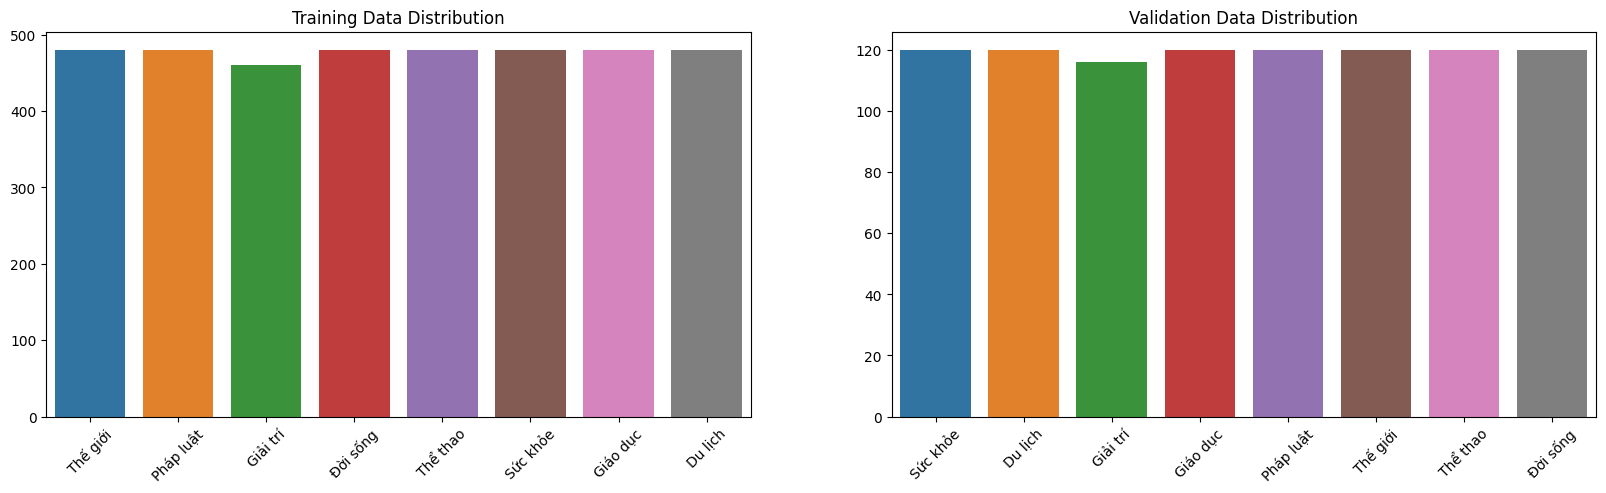

In [ ]:
# plot distribution of training and validation data
import matplotlib.pyplot as plt
import seaborn as sns

# count number of samples in each category

train_count = {}
for i in y_train:
    if i not in train_count:
        train_count[i] = 1
    else:
        train_count[i] += 1

valid_count = {}
for i in y_valid:
    if i not in valid_count:
        valid_count[i] = 1
    else:
        valid_count[i] += 1

train_count = {class_names[k]: v for k, v in train_count.items()}
valid_count = {class_names[k]: v for k, v in valid_count.items()}

fig, ax = plt.subplots(1, 2, figsize=(20, 5))
sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
ax[0].set_title("Training Data Distribution")
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
ax[1].set_title("Validation Data Distribution")
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)
plt.show()

In [ ]:
vectorizer = TfidfVectorizer(min_df=3)
X_train_features = vectorizer.fit_transform(X_train)
X_valid_features = vectorizer.transform(X_valid)
feature_names = vectorizer.get_feature_names_out()

In [ ]:
voca_dict = featurizer.vocabulary_
len(voca_dict)

16455

In [ ]:
def featureHashingTfidf(data, feature_names, num_fea, voca_dict):
  features = []
  tfidf_matrix = data.todense()
  for i in range(tfidf_matrix.shape[0]):
    feature_index = tfidf_matrix[i,:].nonzero()[1]
    tfidf_scores = zip([feature_names[i] for i in feature_index], [tfidf_matrix[0, x] for x in feature_index])
    feature = [0] * num_fea
    for k, v in tfidf_scores:
        fea_index = voca_dict[k] % num_fea
        feature[fea_index] += 1 + v

    features.append(feature)
  return features

In [ ]:
X_train_features_hashing = featureHashingTfidf(X_train_features, feature_names.tolist(), num_fea = 8192 * 2, voca_dict = voca_dict)
X_valid_features_hashing = featureHashingTfidf(X_valid_features, feature_names.tolist(), num_fea = 8192 * 2, voca_dict = voca_dict)

## 1. Multinomial Naive Bayes

### 1.1 Vector hóa dữ liệu

### 1.2 Huấn luyện mô hình

In [ ]:
mNB = MultinomialNB()
mNB.fit(X_train_features_hashing, y_train)

MultinomialNB()

### 1.3 Đánh giá mô hình

Quan sát dựa vào các metrics khác (precision, recall, f1 score, ...)

In [ ]:
%time
y_pred = mNB.predict(X_valid_features_hashing)
print(classification_report(y_valid, y_pred, target_names=class_names))

CPU times: user 4 µs, sys: 0 ns, total: 4 µs
Wall time: 8.11 µs
              precision    recall  f1-score   support

    Giải trí       0.91      0.91      0.91       116
    Đời sống       0.74      0.75      0.75       120
    Thể thao       1.00      0.91      0.95       120
    Thế giới       0.97      0.92      0.94       120
     Du lịch       0.87      0.88      0.88       120
   Pháp luật       0.94      0.97      0.95       120
    Giáo dục       0.91      0.94      0.93       120
    Sức khỏe       0.87      0.92      0.89       120

    accuracy                           0.90       956
   macro avg       0.90      0.90      0.90       956
weighted avg       0.90      0.90      0.90       956



Ma trận nhầm lẫn

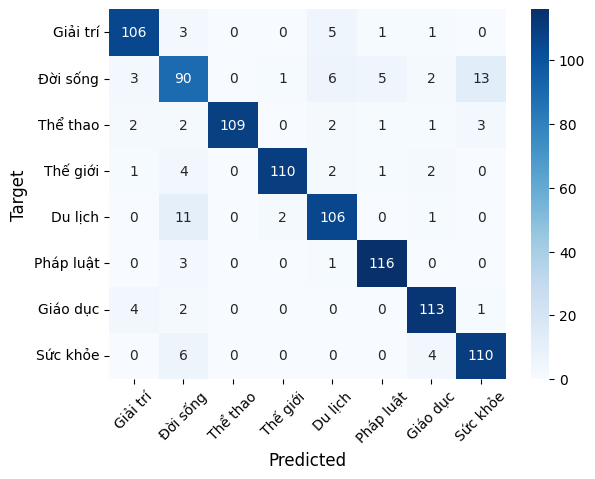

In [ ]:
plot_cm(confusion_matrix(y_valid, y_pred))

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_valid, y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_valid, y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9000
accuracy: 0.8996


## 2. Random Forest

### 2.1. Vector hóa dữ liệu

Sử dụng TF-IDF <br>
min_df = 3: chỉ tính những từ khóa xuất hiện ở ít nhất 3 tài liệu

### 2.2. Huấn luyện mô hình

In [ ]:
clf_rdforest = RandomForestClassifier(n_estimators=100, criterion="gini", random_state=42)  # Set the number of trees as 100
clf_rdforest.fit(X_train_features_hashing, y_train)

RandomForestClassifier(random_state=42)

### 2.3. Kết quả dự đoán

In [ ]:
print(f"Train acc: {clf_rdforest.score(X_train_features_hashing, y_train):.3f}")
print(f"valid acc: {clf_rdforest.score(X_valid_features_hashing, y_valid):.3f}")

Train acc: 1.000
valid acc: 0.932


In [ ]:
%time
y_pred = clf_rdforest.predict(X_valid_features_hashing)

CPU times: user 2 µs, sys: 0 ns, total: 2 µs
Wall time: 7.15 µs


In [ ]:
print(classification_report(y_valid, y_pred, target_names=class_names))

              precision    recall  f1-score   support

    Giải trí       0.96      0.94      0.95       116
    Đời sống       0.87      0.77      0.81       120
    Thể thao       0.99      0.97      0.98       120
    Thế giới       0.98      0.90      0.94       120
     Du lịch       0.92      0.95      0.93       120
   Pháp luật       0.95      0.98      0.97       120
    Giáo dục       0.94      0.97      0.96       120
    Sức khỏe       0.86      0.97      0.91       120

    accuracy                           0.93       956
   macro avg       0.93      0.93      0.93       956
weighted avg       0.93      0.93      0.93       956



In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_valid, y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_valid, y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9313
accuracy: 0.9320


Ma trận nhầm lẫn

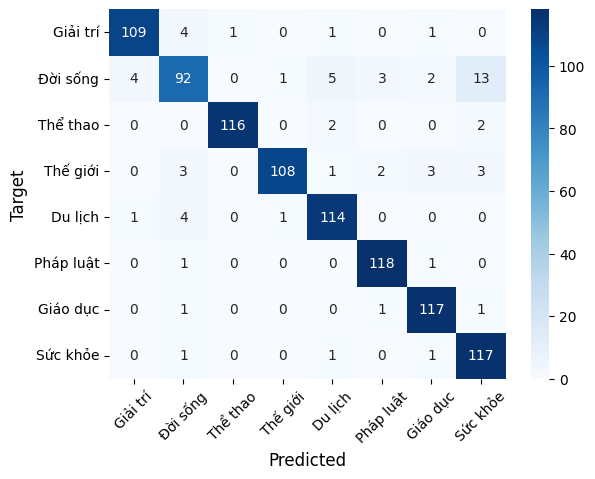

In [ ]:
plot_cm(confusion_matrix(y_valid, y_pred))

## 3. Multinomial Logistic Regression (Softmax Regression)


Multinomial Logistic Regression (Hồi quy Logistic đa thức) có tên gọi khác là hồi quỳ Softmax (`Softmax Regression`) là một mô hình dựa trên `Logistic Regression` sử dụng cho dự đoán để phân lớp 2 nhãn nhưng mở rộng ra cho nhiều nhãn.

$y = \sigma(W^Tx)$

Trong đó:

* $\sigma()$ là hàm kích hoạt
* $W$ là trọng số của các features có được sau quá trình tìm được từ huấn luyện dữ liệu
* $x$ là dữ liệu đầu vào, cụ thể là các features.
----
Để tính toán trên bài toán đa lớp ta cần thiết lập một số điều như sau:

* $W \in R^{N \times M}$, trong đó $N$ tương ứng với số chiều dữ liệu đầu vào, $M$ tương ứng với số lượng nhãn yêu cầu ở đầu ra.

* $x \in R^{N \times 1}$, $x$ là một vector có số lượng phần tử là $N$.

* $\sigma()$, hàm kích hoạt sẽ sử dụng hàm phân phối `Softmax`
---
Lúc này ta có thể dễ dàng nhận ra, khi $W^Tx$ thì đầu ra sẽ là một vector có chiều $M$, cụ thể: $(R^{N \times M})^T \cdot R^{N \times 1} → R^{M \times 1}$


In [ ]:
import numpy as np

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
import pandas as pd
def plot_cm(confusion_mt):
  df_confusion_mt = pd.DataFrame(confusion_mt, index=class_names, columns=class_names)
  ax = sns.heatmap(df_confusion_mt, annot=True, fmt='g', cmap='Blues')
  ax.set_xlabel("Predicted", fontsize=12)
  ax.set_xticklabels(class_names, rotation=45)
  ax.set_ylabel("Target", fontsize=12)
  plt.show()

### 3.2. Huấn luyện mô hình

Huấn luyện mô hình, nhóm sử dụng hàm mất mát được xây dựng từ hàm `log likelihood`, cụ thể như sau:

$$
\text{Negative Log-Likelihood}_i = -\log(y_{\text{pred}}[i, y_{\text{true}}[i]])\\
\text{Loss} = \frac{1}{m} \sum_{i=1}^{m} \text{Negative Log-Likelihood}_i
$$

Hàm grad được cụ thể hóa như sau

$$
Grad = \frac{1}{m} X^T \cdot (y_{pred} - onehot(y_{true}))
$$

----
Trong đó:

* $y_{pred}$ là phân phối xác suất dự đoán của mô hình với 8 nhãn.

* $y_{true}$ là nhãn thực tế của dữ liệu đầu vào, nhãn này có các giá trị thuộc trong các số: {0, 1, 2, 3, 4, 5, 6, 7}

* $X$ là dữ liệu đầu vào
* Hàm onehot là hàm mã hóa lại giá trị của $y_{true}$ thành một vector gồm số 0 và số 1, cụ thể các giá trị tại các nhãn khác bằng 0, còn tại vị trí $y_{true}$ thì bằng 1, ví dụ: $y_{true} = 3$ thì vector sẽ là $[0, 0, 0, 1, 0, 0, 0, 0]$
* $m$ là số mẫu được đưa vào



In [ ]:
from tqdm import tqdm

class LogisticRegression:
    def __init__(self, learning_rate=0.01, num_iter=1000):
        self.learning_rate = learning_rate
        self.num_iter = num_iter
        self.weights = None

    def softmax(self, z):
        return np.exp(z) / np.sum(np.exp(z), axis=1, keepdims=True)

    def cross_entropy_loss(self, y_pred, y_true):
        m = y_true.shape[0]
        log_likelihood = -np.log(y_pred[range(m), y_true])
        loss = np.sum(log_likelihood) / m
        return loss

    def fit(self, X, y, batch_size=32):
        m, n = X.shape

        if self.weights is None:
            self.weights = np.zeros((n, len(np.unique(y))))

        pbar = tqdm(range(self.num_iter), bar_format='{desc} {percentage:3.0f}%|{bar:10}{r_bar}')
        for i in pbar:
            # Data Shuffling
            idx = np.random.permutation(m)
            X = X[idx]
            y = y[idx]

            losses = []
            for j in range(0, m, batch_size):
                X_batch = X[j:j+batch_size]
                y_batch = y[j:j+batch_size]

                z = np.dot(X_batch, self.weights)
                y_pred = self.softmax(z)
                loss = self.cross_entropy_loss(y_pred, y_batch)
                losses.append(loss)
                gradient = np.dot(X_batch.T, (y_pred - np.eye(len(np.unique(y)))[y_batch])) / m
                self.weights -= self.learning_rate * gradient

            pbar.set_description(f"Epoch {i + 1}")
            pbar.set_postfix({"loss":np.mean(losses)})

    def save_weights(self, file_name):
        np.save(file_name, self.weights)

    def load_weights(self, file_name):
        self.weights = np.load(file_name)

    def predict(self, X):
        z = np.dot(X, self.weights)
        return self.softmax(z)

**Trường hợp quá trình huấn luyện bị gián đoạn do số lượng features quá lớn**

Epoch 1000:  100%|██████████| 1000/1000 [12:26<00:00,  1.34it/s, loss=0.0758]


              precision    recall  f1-score   support

    Giải trí       0.96      0.94      0.95       116
    Đời sống       0.79      0.88      0.83       120
    Thể thao       0.98      0.97      0.97       120
    Thế giới       0.98      0.93      0.95       120
     Du lịch       0.93      0.91      0.92       120
   Pháp luật       0.97      0.97      0.97       120
    Giáo dục       0.97      0.96      0.97       120
    Sức khỏe       0.93      0.96      0.94       120

    accuracy                           0.94       956
   macro avg       0.94      0.94      0.94       956
weighted avg       0.94      0.94      0.94       956



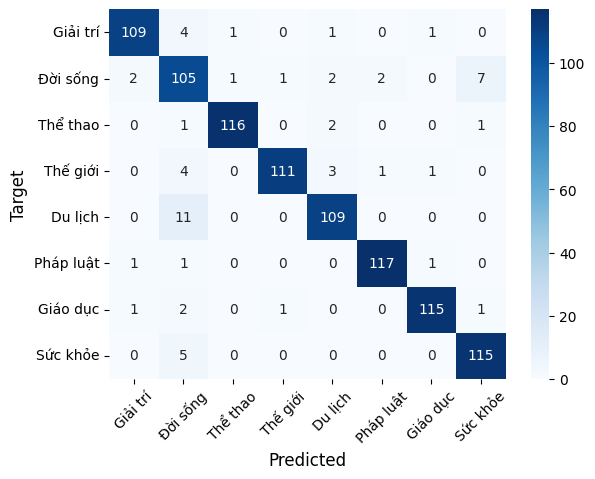

In [ ]:
# import pickle
LR = LogisticRegression(learning_rate=0.1, num_iter=1000)
y_train = np.array(y_train)
LR.fit(np.array(X_train_features_hashing), y_train)

y_pred = LR.predict(np.array(X_valid_features_hashing))
y_pred = np.argmax(y_pred, axis=1)
report = classification_report(y_valid, y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_valid, y_pred)
plot_cm(cm)

In [ ]:
from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_valid, y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_valid, y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9391
accuracy: 0.9383


# Testing


In [ ]:
!gdown 192p1wAX5lKMH2acAINuU-ZbCs94cP9D9

Downloading...
From: https://drive.google.com/uc?id=192p1wAX5lKMH2acAINuU-ZbCs94cP9D9
To: /content/news_test_cleaned.csv
100% 3.96M/3.96M [00:00<00:00, 120MB/s]


In [ ]:
import pandas as pd
test_set = pd.read_csv('news_test_cleaned.csv')

In [ ]:
test_set = test_set.dropna()

In [ ]:
test_set["title_description_content"] = (test_set["title"] + " ") * 10 + (test_set["description"] + " ") * 3  + test_set["content"]

In [ ]:
test_set["title_description_content"].to_list()

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
test_set.isnull().sum()

title                        0
description                  0
content                      0
author                       0
time                         0
link                         0
category                     0
title_description_content    0
dtype: int64

In [ ]:
class_names

['Giải trí',
 'Đời sống',
 'Thể thao',
 'Thế giới',
 'Du lịch',
 'Pháp luật',
 'Giáo dục',
 'Sức khỏe']

In [ ]:
def class_name_to_id(class_name):
    return list(class_names).index(class_name)

In [ ]:
test_set['category_id'] = test_set['category'].apply(class_name_to_id)

In [ ]:
X_test = test_set.title_description_content.to_list()
y_test = test_set.category_id.to_list()

In [ ]:
X_test

Output hidden; open in https://colab.research.google.com to view.

<ipython-input-32-7675e9965122>:37: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
<ipython-input-32-7675e9965122>:39: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
<ipython-input-32-7675e9965122>:40: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
<ipython-input-32-7675e9965122>:42: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)
<ipython-input-32-

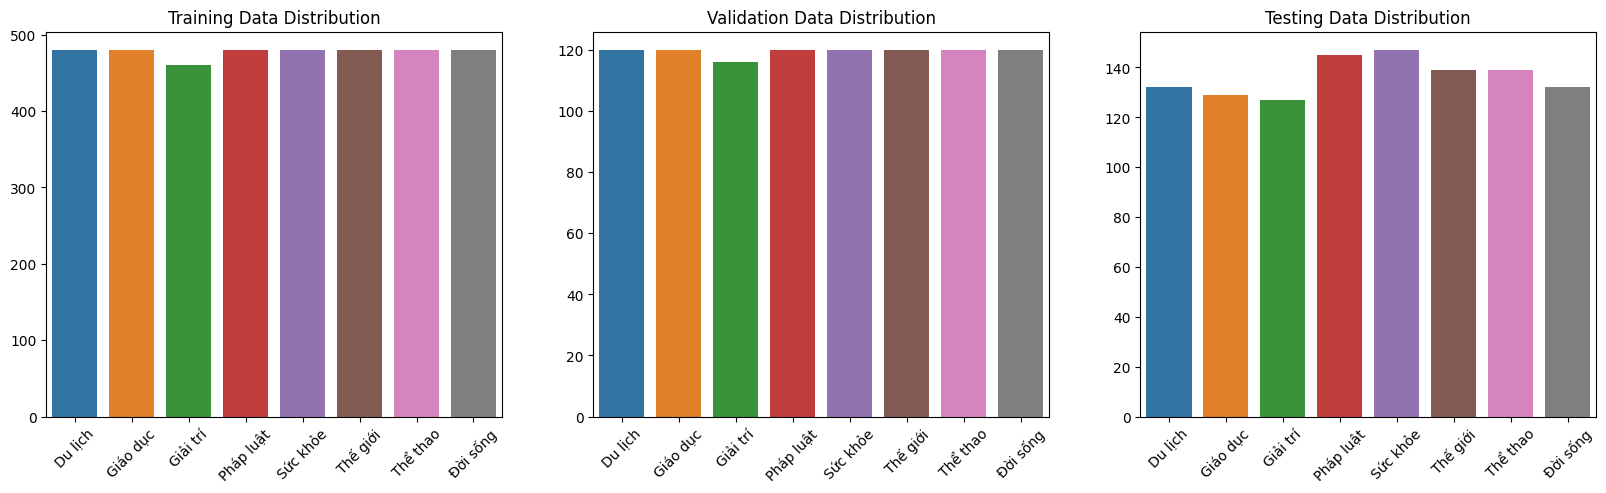

In [ ]:
# plot distribution of training and validation data
import matplotlib.pyplot as plt
import seaborn as sns

# count number of samples in each category

train_count = {}
for i in y_train:
    if i not in train_count:
        train_count[i] = 1
    else:
        train_count[i] += 1

valid_count = {}
for i in y_valid:
    if i not in valid_count:
        valid_count[i] = 1
    else:
        valid_count[i] += 1

test_count = {}
for i in y_test:
    if i not in test_count:
        test_count[i] = 1
    else:
        test_count[i] += 1

train_count = {class_names[k]: v for k, v in train_count.items()}
valid_count = {class_names[k]: v for k, v in valid_count.items()}
test_count = {class_names[k]: v for k, v in test_count.items()}

train_count = {k: v for k, v in sorted(train_count.items())}
valid_count = {k: v for k, v in sorted(valid_count.items())}
test_count = {k: v for k, v in sorted(test_count.items())}

fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.barplot(x=list(train_count.keys()), y=list(train_count.values()), ax=ax[0], palette='tab10')
ax[0].set_title("Training Data Distribution")
ax[0].set_xticklabels(ax[0].get_xticklabels(), rotation=45)
sns.barplot(x=list(valid_count.keys()), y=list(valid_count.values()), ax=ax[1], palette='tab10')
ax[1].set_title("Validation Data Distribution")
ax[1].set_xticklabels(ax[1].get_xticklabels(), rotation=45)

sns.barplot(x=list(test_count.keys()), y=list(test_count.values()), ax=ax[2], palette='tab10')
ax[2].set_title("Testing Data Distribution")
ax[2].set_xticklabels(ax[2].get_xticklabels(), rotation=45)
plt.show()

In [ ]:
X_test_features = vectorizer.transform(X_test)

In [ ]:
X_test_features_hashing = featureHashingTfidf(X_test_features, feature_names.tolist(), num_fea = 8192 * 2, voca_dict = voca_dict)

In [ ]:
clf_rdforest_y_pred = clf_rdforest.predict(X_test_features_hashing)

f1 score: 0.9022
accuracy: 0.9055
              precision    recall  f1-score   support

    Giải trí       0.91      0.92      0.91       127
    Đời sống       0.85      0.62      0.72       132
    Thể thao       0.96      0.98      0.97       139
    Thế giới       0.98      0.90      0.94       139
     Du lịch       0.89      0.92      0.91       132
   Pháp luật       0.91      0.97      0.94       145
    Giáo dục       0.86      0.99      0.92       129
    Sức khỏe       0.87      0.93      0.90       147

    accuracy                           0.91      1090
   macro avg       0.90      0.90      0.90      1090
weighted avg       0.91      0.91      0.90      1090



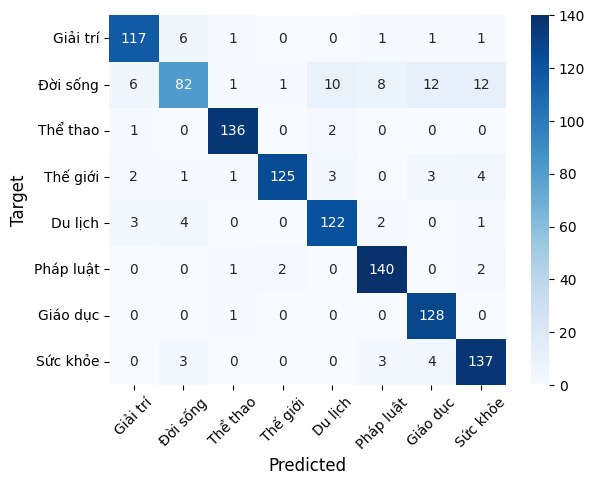

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_test, clf_rdforest_y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_test, clf_rdforest_y_pred)
print(f"accuracy: {acc:.4f}")
report = classification_report(y_test, clf_rdforest_y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_test, clf_rdforest_y_pred)
plot_cm(cm)

accuracy: 0.9385
              precision    recall  f1-score   support

    Giải trí       0.95      0.98      0.97       127
    Đời sống       0.86      0.81      0.84       132
    Thể thao       0.96      0.99      0.97       139
    Thế giới       0.98      0.90      0.94       139
     Du lịch       0.90      0.93      0.91       132
   Pháp luật       0.95      0.98      0.96       145
    Giáo dục       0.95      0.98      0.96       129
    Sức khỏe       0.95      0.94      0.95       147

    accuracy                           0.94      1090
   macro avg       0.94      0.94      0.94      1090
weighted avg       0.94      0.94      0.94      1090



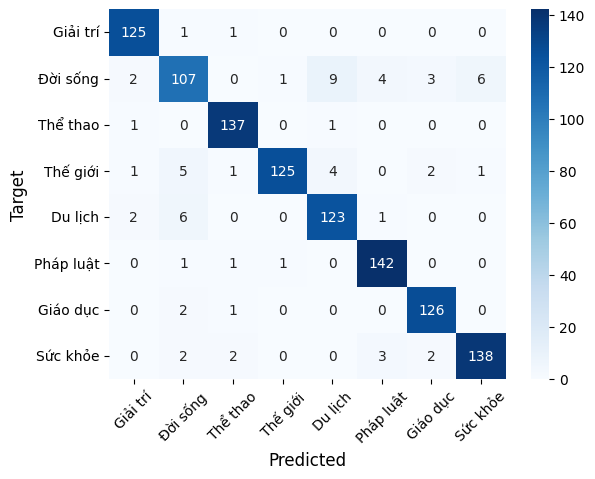

In [ ]:
LR_y_pred = LR.predict(np.array(X_test_features_hashing))
LR_y_pred = np.argmax(LR_y_pred, axis=1)

# calculate accuracy
acc = accuracy_score(y_test, LR_y_pred)
print(f"accuracy: {acc:.4f}")
report = classification_report(y_test, LR_y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_test, LR_y_pred)
plot_cm(cm)

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_test, LR_y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_test, LR_y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.9380
accuracy: 0.9385


accuracy: 0.9000
              precision    recall  f1-score   support

    Giải trí       0.91      0.94      0.93       127
    Đời sống       0.72      0.70      0.71       132
    Thể thao       0.98      0.95      0.96       139
    Thế giới       0.98      0.90      0.94       139
     Du lịch       0.84      0.89      0.86       132
   Pháp luật       0.93      0.98      0.95       145
    Giáo dục       0.89      0.94      0.91       129
    Sức khỏe       0.94      0.90      0.92       147

    accuracy                           0.90      1090
   macro avg       0.90      0.90      0.90      1090
weighted avg       0.90      0.90      0.90      1090



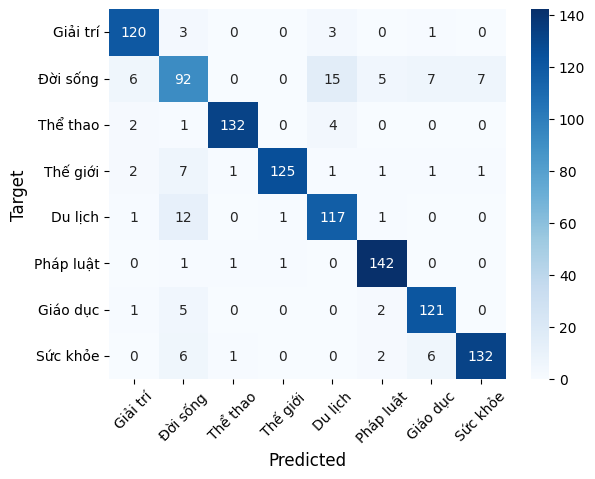

In [ ]:
mNB_y_pred = mNB.predict(X_test_features_hashing)
# calculate accuracy
acc = accuracy_score(y_test, mNB_y_pred)
print(f"accuracy: {acc:.4f}")
report = classification_report(y_test, mNB_y_pred, target_names=class_names)
print(report)
cm = confusion_matrix(y_test, mNB_y_pred)
plot_cm(cm)

In [ ]:
# import f1_score, accuracy_score, confusion_matrix

from sklearn.metrics import f1_score, accuracy_score

# calculate f1 score
f1 = f1_score(y_test, mNB_y_pred, average='weighted')
print(f"f1 score: {f1:.4f}")

# calculate accuracy
acc = accuracy_score(y_test, mNB_y_pred)
print(f"accuracy: {acc:.4f}")

f1 score: 0.8998
accuracy: 0.9000
